# Stage 5 — Understand the trained MobileViT

This notebook inspects the actual trained `timm` model instead of recreating MobileViT from diagrams. It records parameters and observed tensor shapes for every MobileViT block, then produces a block-anatomy diagram for the presentation and the later CrackFusion fork decision.

In [59]:
%pip install -q timm matplotlib

## 1. Restore the trained model and one real validation tile

In [60]:
import csv
import json
from pathlib import Path

import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch
from PIL import Image
import timm
from timm.data import create_transform
import torch

AUDIT_DIR = Path("outputs/sdnet2018_audit")
TRAINING_DIR = Path("outputs/mobilevit_xs/development_training")
OUTPUT_DIR = Path("outputs/mobilevit_xs/architecture_inspection")
CHECKPOINT_PATH = TRAINING_DIR / "best_mobilevit_xs.pt"
SUMMARY_PATH = AUDIT_DIR / "stage_two_summary.json"
MANIFEST_PATH = AUDIT_DIR / "development_manifest.csv"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

missing = [str(path) for path in [CHECKPOINT_PATH, SUMMARY_PATH, MANIFEST_PATH] if not path.exists()]
if missing:
    raise FileNotFoundError(f"Missing earlier-stage artifacts: {missing}")

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "mps" if torch.backends.mps.is_available() else "cpu")
checkpoint = torch.load(CHECKPOINT_PATH, map_location=DEVICE, weights_only=False)
model = timm.create_model(checkpoint["model_name"], pretrained=False, num_classes=1)
model.load_state_dict(checkpoint["model_state_dict"])
model = model.to(DEVICE).eval()
transform = create_transform(**checkpoint["data_config"], is_training=False)

stage_two_summary = json.loads(SUMMARY_PATH.read_text(encoding="utf-8"))
dataset_root = Path(stage_two_summary["dataset_root"])
with MANIFEST_PATH.open(newline="", encoding="utf-8") as stream:
    sample_row = next(row for row in csv.DictReader(stream) if row["split"] == "dev_validation")
with Image.open(dataset_root / sample_row["path"]) as image:
    batch = transform(image.convert("RGB")).unsqueeze(0).to(DEVICE)

print({"device": str(DEVICE), "sample": sample_row["path"], "input_shape": list(batch.shape)})

{'device': 'cuda', 'sample': 'D/CD/7001-169.jpg', 'input_shape': [1, 3, 256, 256]}


## 2. Locate MobileViT blocks from the running model

No stage names are hard-coded. Blocks are selected from their runtime class, so this report describes the exact checkpoint implementation.

In [61]:
mobilevit_blocks = [
    (name, module)
    for name, module in model.named_modules()
    if "mobilevitblock" in module.__class__.__name__.lower()
]
if not mobilevit_blocks:
    raise RuntimeError("No MobileViTBlock modules were found in the loaded model.")

total_parameters = sum(parameter.numel() for parameter in model.parameters())
print(f"Model: {model.__class__.__name__} | parameters: {total_parameters:,}")
for name, block in mobilevit_blocks:
    parameters = sum(parameter.numel() for parameter in block.parameters())
    children = [f"{child_name}:{child.__class__.__name__}" for child_name, child in block.named_children()]
    print(f"{name} | {block.__class__.__name__} | {parameters:,} parameters")
    print("  " + " -> ".join(children))

Model: ByobNet | parameters: 1,933,233
stages.2.1 | MobileVitBlock | 273,024 parameters
  conv_kxk:ConvNormAct -> conv_1x1:Conv2d -> transformer:Sequential -> norm:LayerNorm -> conv_proj:ConvNormAct -> conv_fusion:ConvNormAct
stages.3.1 | MobileVitBlock | 658,800 parameters
  conv_kxk:ConvNormAct -> conv_1x1:Conv2d -> transformer:Sequential -> norm:LayerNorm -> conv_proj:ConvNormAct -> conv_fusion:ConvNormAct
stages.4.1 | MobileVitBlock | 779,760 parameters
  conv_kxk:ConvNormAct -> conv_1x1:Conv2d -> transformer:Sequential -> norm:LayerNorm -> conv_proj:ConvNormAct -> conv_fusion:ConvNormAct


## 3. Record real execution order and tensor shapes

Hooks observe the block boundaries and their direct components during one inference pass. Patch unfold/fold operations may be functional operations rather than named modules, so they are represented in the conceptual diagram in Section 5.

In [62]:
def tensor_shapes(value):
    if isinstance(value, torch.Tensor):
        return [list(value.shape)]
    if isinstance(value, (tuple, list)):
        shapes = []
        for item in value:
            shapes.extend(tensor_shapes(item))
        return shapes
    return []

block_records = {}
component_execution = []
handles = []

def block_hook(name):
    def capture(module, inputs, output):
        block_records[name] = {
            "type": module.__class__.__name__,
            "input_shapes": tensor_shapes(inputs),
            "output_shapes": tensor_shapes(output),
            "parameters": sum(parameter.numel() for parameter in module.parameters()),
        }
    return capture

def component_hook(block_name, component_name):
    def capture(module, inputs, output):
        component_execution.append({
            "block": block_name,
            "component": component_name,
            "type": module.__class__.__name__,
            "input_shapes": tensor_shapes(inputs),
            "output_shapes": tensor_shapes(output),
            "parameters": sum(parameter.numel() for parameter in module.parameters()),
        })
    return capture

for block_name, block in mobilevit_blocks:
    handles.append(block.register_forward_hook(block_hook(block_name)))
    for component_name, component in block.named_children():
        handles.append(component.register_forward_hook(component_hook(block_name, component_name)))

with torch.inference_mode():
    logit = model(batch)
for handle in handles:
    handle.remove()

assert len(block_records) == len(mobilevit_blocks)
print("Output logit:", logit.item())
for name, record in block_records.items():
    print(f"{name}: {record['input_shapes']} -> {record['output_shapes']} | {record['parameters']:,} parameters")
print("Observed direct-component executions:", len(component_execution))

Output logit: 0.2911137342453003
stages.2.1: [[1, 64, 32, 32]] -> [[1, 64, 32, 32]] | 273,024 parameters
stages.3.1: [[1, 80, 16, 16]] -> [[1, 80, 16, 16]] | 658,800 parameters
stages.4.1: [[1, 96, 8, 8]] -> [[1, 96, 8, 8]] | 779,760 parameters
Observed direct-component executions: 18


## 4. Parameters per top-level stage and per MobileViT block

In [63]:
stage_parameter_rows = [
    {
        "stage": name,
        "type": module.__class__.__name__,
        "parameters": sum(parameter.numel() for parameter in module.parameters()),
    }
    for name, module in model.named_children()
]
assert sum(row["parameters"] for row in stage_parameter_rows) == total_parameters

with (OUTPUT_DIR / "stage_parameters.csv").open("w", newline="", encoding="utf-8") as stream:
    writer = csv.DictWriter(stream, fieldnames=["stage", "type", "parameters"])
    writer.writeheader()
    writer.writerows(stage_parameter_rows)

with (OUTPUT_DIR / "mobilevit_components.csv").open("w", newline="", encoding="utf-8") as stream:
    writer = csv.DictWriter(
        stream,
        fieldnames=["block", "component", "type", "input_shapes", "output_shapes", "parameters"],
    )
    writer.writeheader()
    writer.writerows(component_execution)

print(f"{'Stage':<20}{'Type':<24}{'Parameters':>14}")
for row in stage_parameter_rows:
    print(f"{row['stage']:<20}{row['type']:<24}{row['parameters']:>14,}")

Stage               Type                        Parameters
stem                ConvNormAct                        464
stages              Sequential                   1,894,752
final_conv          ConvNormAct                     37,632
head                ClassifierHead                     385


## 5. MobileViT block anatomy

A MobileViT block keeps a local convolutional path, projects the feature map into a token-friendly representation, performs global Transformer processing, folds the tokens back to a spatial map, and fuses them with local features. The labels below use the exact first block shapes observed above.

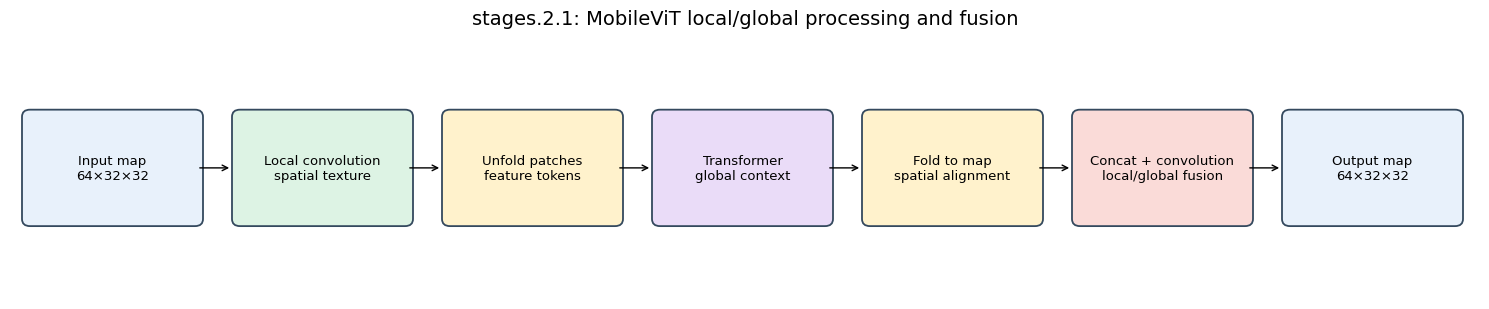

Saved /content/outputs/mobilevit_xs/architecture_inspection/mobilevit_block_anatomy.png


In [64]:
first_name = next(iter(block_records))
first_record = block_records[first_name]
input_shape = first_record["input_shapes"][0]
output_shape = first_record["output_shapes"][0]
steps = [
    (f"Input map\n{input_shape[1]}×{input_shape[2]}×{input_shape[3]}", "#E8F1FB"),
    ("Local convolution\nspatial texture", "#DDF3E4"),
    ("Unfold patches\nfeature tokens", "#FFF2CC"),
    ("Transformer\nglobal context", "#EADCF8"),
    ("Fold to map\nspatial alignment", "#FFF2CC"),
    ("Concat + convolution\nlocal/global fusion", "#FADBD8"),
    (f"Output map\n{output_shape[1]}×{output_shape[2]}×{output_shape[3]}", "#E8F1FB"),
]

figure, axis = plt.subplots(figsize=(15, 3.2))
axis.set_xlim(0, len(steps) * 2.1)
axis.set_ylim(0, 3)
axis.axis("off")
for index, (label, color) in enumerate(steps):
    x = index * 2.1 + 0.2
    axis.add_patch(FancyBboxPatch(
        (x, 0.9), 1.65, 1.15, boxstyle="round,pad=0.08",
        facecolor=color, edgecolor="#34495E", linewidth=1.3,
    ))
    axis.text(x + 0.825, 1.475, label, ha="center", va="center", fontsize=9.5)
    if index < len(steps) - 1:
        axis.annotate("", xy=(x + 2.02, 1.475), xytext=(x + 1.67, 1.475), arrowprops={"arrowstyle": "->"})
axis.set_title(f"{first_name}: MobileViT local/global processing and fusion", fontsize=14)
figure.tight_layout()
diagram_path = OUTPUT_DIR / "mobilevit_block_anatomy.png"
figure.savefig(diagram_path, dpi=180, bbox_inches="tight")
plt.show()
print("Saved", diagram_path.resolve())

## 6. Save the inspection report

In [65]:
report = {
    "model_name": checkpoint["model_name"],
    "total_parameters": total_parameters,
    "sample_path": sample_row["path"],
    "input_shape": list(batch.shape),
    "output_shape": list(logit.shape),
    "mobilevit_block_count": len(mobilevit_blocks),
    "mobilevit_blocks": block_records,
    "top_level_stage_parameters": stage_parameter_rows,
    "component_execution": component_execution,
    "diagram": str(diagram_path.resolve()),
    "interpretation": (
        "Convolution preserves local crack texture; patch-wise Transformer processing adds global context; "
        "the folded global representation is fused back with spatial features."
    ),
}
report_path = OUTPUT_DIR / "architecture_report.json"
report_path.write_text(json.dumps(report, indent=2) + "\n", encoding="utf-8")

for path in [report_path, diagram_path, OUTPUT_DIR / "stage_parameters.csv", OUTPUT_DIR / "mobilevit_components.csv"]:
    assert path.exists(), path
print(json.dumps({
    "mobilevit_blocks": len(mobilevit_blocks),
    "block_names": list(block_records),
    "total_parameters": total_parameters,
    "report": str(report_path.resolve()),
}, indent=2))

{
  "mobilevit_blocks": 3,
  "block_names": [
    "stages.2.1",
    "stages.3.1",
    "stages.4.1"
  ],
  "total_parameters": 1933233,
  "report": "/content/outputs/mobilevit_xs/architecture_inspection/architecture_report.json"
}


## 7. Bundle every generated artifact for local export

This archive includes everything saved under `/content/outputs`: audit/development manifests, summaries, the best checkpoint, training history, validation predictions and metrics, figures, and architecture reports. The original dataset is excluded because it already exists locally.

In [ ]:
import hashlib
import platform
import sys
from zipfile import ZIP_DEFLATED, ZipFile

outputs_root = Path("/content/outputs")
export_path = Path("/content/mobilevit_stages_1_to_5_export.zip")
if not outputs_root.exists():
    raise FileNotFoundError(outputs_root)

runtime_metadata = {
    "python": sys.version,
    "platform": platform.platform(),
    "torch": torch.__version__,
    "timm": timm.__version__,
    "device": str(DEVICE),
    "cuda_device": torch.cuda.get_device_name(0) if torch.cuda.is_available() else None,
}
(outputs_root / "runtime_environment.json").write_text(
    json.dumps(runtime_metadata, indent=2) + "\n", encoding="utf-8"
)

artifact_files = sorted(path for path in outputs_root.rglob("*") if path.is_file())
export_manifest = []
for path in artifact_files:
    digest = hashlib.sha256()
    with path.open("rb") as stream:
        while chunk := stream.read(1024 * 1024):
            digest.update(chunk)
    export_manifest.append({
        "path": path.relative_to(outputs_root.parent).as_posix(),
        "bytes": path.stat().st_size,
        "sha256": digest.hexdigest(),
    })

manifest_path = outputs_root / "export_manifest.json"
manifest_path.write_text(json.dumps(export_manifest, indent=2) + "\n", encoding="utf-8")
artifact_files = sorted(path for path in outputs_root.rglob("*") if path.is_file())
with ZipFile(export_path, "w", compression=ZIP_DEFLATED, compresslevel=6) as archive:
    for path in artifact_files:
        archive.write(path, path.relative_to(outputs_root.parent))

with ZipFile(export_path) as archive:
    bad_member = archive.testzip()
assert bad_member is None, f"Corrupt ZIP member: {bad_member}"
print({
    "archive": str(export_path),
    "files": len(artifact_files),
    "size_mib": round(export_path.stat().st_size / 1024**2, 2),
})
print("In the VS Code Colab sidebar, open Contents, right-click this ZIP, and choose Download.")

## 8. Copy the export bundle to Google Drive

First run **Colab: Mount Google Drive to Server...** from the VS Code command palette. Then run this cell. A single ZIP is used instead of thousands of individual Drive writes.

In [ ]:
import shutil

drive_root = Path("/content/drive/MyDrive")
if not drive_root.exists():
    raise RuntimeError(
        "Google Drive is not mounted. Run 'Colab: Mount Google Drive to Server...' in VS Code first."
    )

drive_export_dir = drive_root / "major_project_exports"
drive_export_dir.mkdir(parents=True, exist_ok=True)
drive_export_path = drive_export_dir / export_path.name
shutil.copy2(export_path, drive_export_path)
shutil.copy2(manifest_path, drive_export_dir / manifest_path.name)

local_digest = hashlib.sha256(export_path.read_bytes()).hexdigest()
drive_digest = hashlib.sha256(drive_export_path.read_bytes()).hexdigest()
assert local_digest == drive_digest, "Google Drive copy checksum mismatch"
(drive_export_dir / f"{export_path.name}.sha256").write_text(
    f"{drive_digest}  {export_path.name}\n", encoding="utf-8"
)
print({
    "google_drive_archive": str(drive_export_path),
    "size_mib": round(drive_export_path.stat().st_size / 1024**2, 2),
    "sha256": drive_digest,
})

## Stage 5 exit criterion

Stage 5 is complete when every runtime MobileViT block has an observed input/output shape, execution-order component report, and parameter count; the top-level parameter total matches the complete model; and the block-anatomy diagram renders. The next implementation step is the research-valid baseline or, for architecture prototyping, the explicit CrackFusion-Tiny branch split.